# 05 · MLP ve derin öğrenme

Bu deneyde yapay sinir ağının bir arıza skorunu nasıl hesapladığını, hatasından nasıl öğrendiğini ve klasik modellerle aynı veride nasıl karşılaştırıldığını inceliyoruz. [Türkçe öğrenme rehberi](../docs/deep_learning.md) kavramları sayısal örneklerle açıklar.

Önceki çalışmada XGBoost’un 2.000 test kaydındaki sonuçları görüldü. Aynı küme gelecek deneyler için tamamen yeni bir doğrulama kaynağı değildir. Burada bütün karşılaştırmalar 8.000 eğitim kaydının doğrulama katlarıyla yapılır. AI4I 2020 sentetiktir ve sonuçları gerçek fabrika performansını garanti etmez.

## 1. Ortamı hazırlama

PyTorch’un CPU paketini doğruluyoruz. Veri ve kat sıralaması için önceki aşamanın fonksiyonlarını kullanan ortak eğitim modüllerini yüklüyoruz. Böylece notebook ve komut satırı aynı deneyi çalıştırır.

In [1]:
from pathlib import Path
import sys
import torch
from IPython.display import Image, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.mlp_model import FailureMLP
from src.train_mlp import (
    OUTPUT, compare_with_classical, cross_validate_mlp,
    load_development_data, save_results,
)

assert torch.version.cuda is None
print(f"PyTorch {torch.__version__} · CPU")

PyTorch 2.14.1+cpu · CPU


## 2. Bir nöron ileri ve geri yönde nasıl çalışır?

Bir **nöron** girdileri **ağırlıklarla (weights)** çarpar ve toplama bir **bias** ekler. Klasik **perceptron**, bu toplamın eşik üzerinde olup olmamasına göre 0 veya 1 döndürür. Bu örnekte ağırlıklı toplamı, negatifleri sıfırlayan **ReLU**’yu ve ham değeri 0 ile 1 arasına taşıyan **Sigmoid**’i yan yana görüyoruz.

**Forward propagation** tahmin hesabıdır. **Kayıp fonksiyonu** tahminin gerçek etiketle uyumsuzluğunu ölçer. **Backpropagation** kaybın ağırlıklara göre türevlerini hesaplar. Son satır, **gradient descent** fikrini örnekler. Kaybı düşürmek için ağırlığı gradyanın ters yönünde küçük bir adım taşırız.

In [2]:
features = torch.tensor([2.0, 1.0])
weights = torch.tensor([0.5, -0.2], requires_grad=True)
bias = 0.1
logit = features @ weights + bias
loss = torch.nn.functional.binary_cross_entropy_with_logits(logit, torch.tensor(1.0))
loss.backward()

print(f"Logit = {logit.item():.2f} | ReLU = {torch.relu(logit).item():.2f}")
print(f"Sigmoid = {torch.sigmoid(logit).item():.3f} | Kayıp = {loss.item():.3f}")
print("Gradyanlar", weights.grad.tolist())
print("Bir gradyan inişi adımı", (weights.detach() - 0.001 * weights.grad).tolist())

Logit = 0.90 | ReLU = 0.90
Sigmoid = 0.711 | Kayıp = 0.341
Gradyanlar [-0.5781010389328003, -0.28905051946640015]
Bir gradyan inişi adımı [0.5005781054496765, -0.19971095025539398]


## 3. Ağın katmanları ve verinin hazırlanması

**Artificial Neural Network (ANN)**, birbirine bağlı nöronlardan oluşur. **MLP**, ölçümleri ileri yönde katmanlardan geçiren bir ANN türüdür. Girdi katmanı beş sayısal sensör ölçümü ve üç one-hot ürün tipi sütununu alır. İki gizli katman ReLU ile doğrusal olmayan ilişkiler öğrenir. Çıktı katmanı tek ham logit verir.

**Makine öğrenmesi** veriden öğrenen yöntemlerin genel adıdır. **Derin öğrenme** çok katmanlı sinir ağlarıyla ara temsiller öğrenen bir alt alandır. Örneğin karar ağacı tork eşiğinde dallanır, MLP ise tork ve devir bileşimini birden fazla gizli nöronda temsil edebilir.

PostgreSQL görünümünden önceki sıralama ve ayrımla yalnızca geliştirmede kullanılacak bölümü alıyoruz. Ağın katmanlarını yazdırarak boyutların deneyle eşleştiğini kontrol ediyoruz.

In [3]:
X_train, y_train = load_development_data()
print(f"Eğitim kaydı = {len(y_train)} | Arıza = {int(y_train.sum())}")
print(FailureMLP())

Eğitim kaydı = 8000 | Arıza = 271
FailureMLP(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 4. Beş katı eğitme

Her katta ölçekleme, one-hot kodlama ve pozitif sınıf ağırlığı yalnızca 6.400 eğitim kaydından öğrenilir. 1.600 kayıt doğrulama içindir. **BCEWithLogitsLoss** ham logit alır ve arıza örneklerine katın normal/arıza oranına göre ağırlık verir.

**Batch size** bir güncellemedeki kayıt sayısıdır. Burada 64 kayıttır. **Epoch** tüm eğitim kayıtlarının bir kez işlenmesidir. Burada her epoch 100 batch içerir. **Learning rate** güncellemenin ölçeğidir. **Adam**, gradyanların hareketli istatistiklerini kullanarak parametrelerin güncellemesini uyarlar. Her kat 0,001 öğrenme oranı ve sabit tohumla 50 epoch çalışır. Doğrulama değerlerini izler, rapor için önceden belirlenen 50. epoch’u kullanırız.

In [4]:
folds, history, oof_scores = cross_validate_mlp(X_train, y_train)
display(folds.round(4))

,fold,epoch,pos_weight,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
0,1,50,28.4931,0.9050,0.8972,0.2474,0.8889,0.3871,0.9452,0.6078
1,2,50,28.4931,0.8962,0.8927,0.2308,0.8889,0.3664,0.9564,0.5648
2,3,50,28.4931,0.9200,0.8871,0.2771,0.8519,0.4182,0.9654,0.6662
3,4,50,28.4931,0.9256,0.9526,0.3099,0.9815,0.4711,0.9904,0.8192
4,5,50,28.6296,0.9069,0.8904,0.2526,0.8727,0.3918,0.9635,0.7218


## 5. Klasik modellerle karşılaştırma

Altı klasik modeli aynı beş katta yeniden değerlendiriyoruz. Kat ortalamalarını karşılaştırıp arıza sınıfı seyrek olduğu için modelleri **Average Precision** ile sıralıyoruz. MLP skorları Sigmoid ile elde edilir ve sınıf tahmini için önceden belirlenen 0,5 eşiği kullanılır. Bu eşik ağırlıklı eğitimle kalibre edilmiş bir olasılık anlamına gelmez.

In [5]:
comparison = compare_with_classical(X_train, y_train, folds)
display(comparison.loc[:, ["model", *[c for c in comparison if c.endswith("_mean")]]].round(4))
print(f"En yüksek ortalama AP: {comparison.iloc[0]['model']}")

,model,accuracy_mean,balanced_accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,average_precision_mean
0,XGBoost,0.9496,0.8973,0.3902,0.8412,0.5314,0.9740,0.7643
1,Random Forest,0.9776,0.6874,0.9158,0.3761,0.5309,0.9625,0.7515
2,MLP,0.9108,0.9040,0.2636,0.8968,0.4069,0.9641,0.6759
3,SVM,0.9162,0.9032,0.2745,0.8892,0.4190,0.9624,0.6442
4,Logistic Regression,0.8262,0.8192,0.1412,0.8116,0.2405,0.9030,0.4341
5,Decision Tree,0.9752,0.7787,0.6563,0.5679,0.6076,0.7787,0.3934
6,Dummy Classifier,0.9661,0.5000,0.0000,0.0000,0.0000,0.5000,0.0339


En yüksek ortalama AP: XGBoost


## 6. Eğitim ve doğrulama grafiklerini okuma

Eğitim kaybı düşerken doğrulama AP uzun süre düşüyorsa **overfitting** olasılığı vardır. Eğitim kaybı yüksek ve doğrulama AP düşük kalıyorsa **underfitting** olasılığı vardır. Tek bir dalgalanma teşhis için yeterli değildir.

ROC ve Precision–Recall eğrileri, her satırın dışarıda kaldığı doğrulama katındaki skorla çizilir. Bu birleşik eğrilerin özeti, model seçimi için kullandığımız kat ortalamasından farklı olabilir. CSV’ler ve grafikler önceki aşamanın sonuçlarından ayrı konuma yazılır.

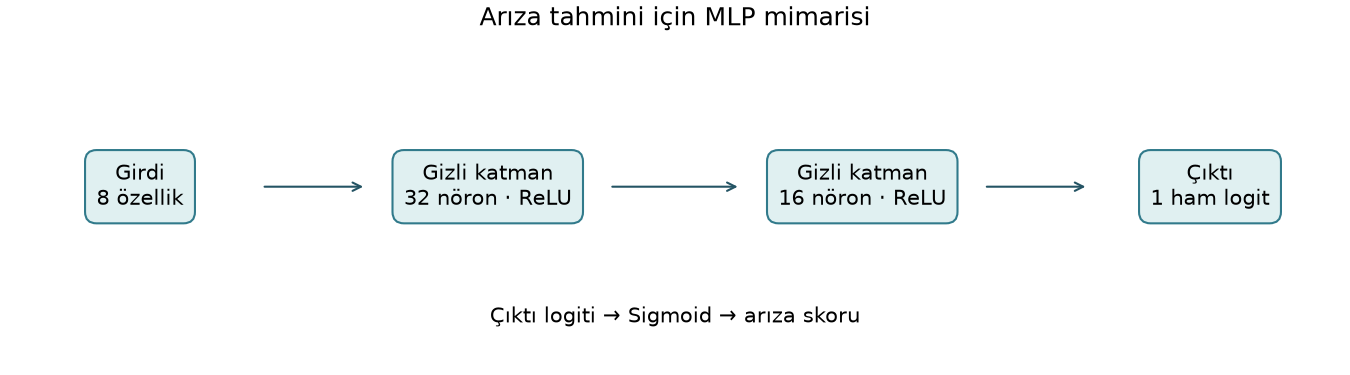

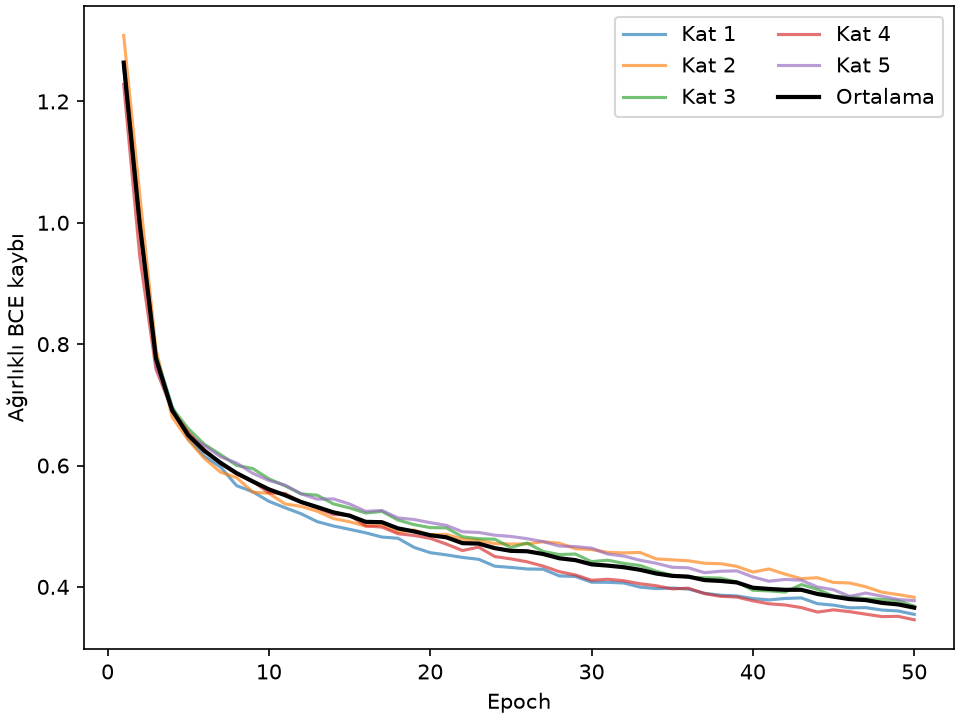

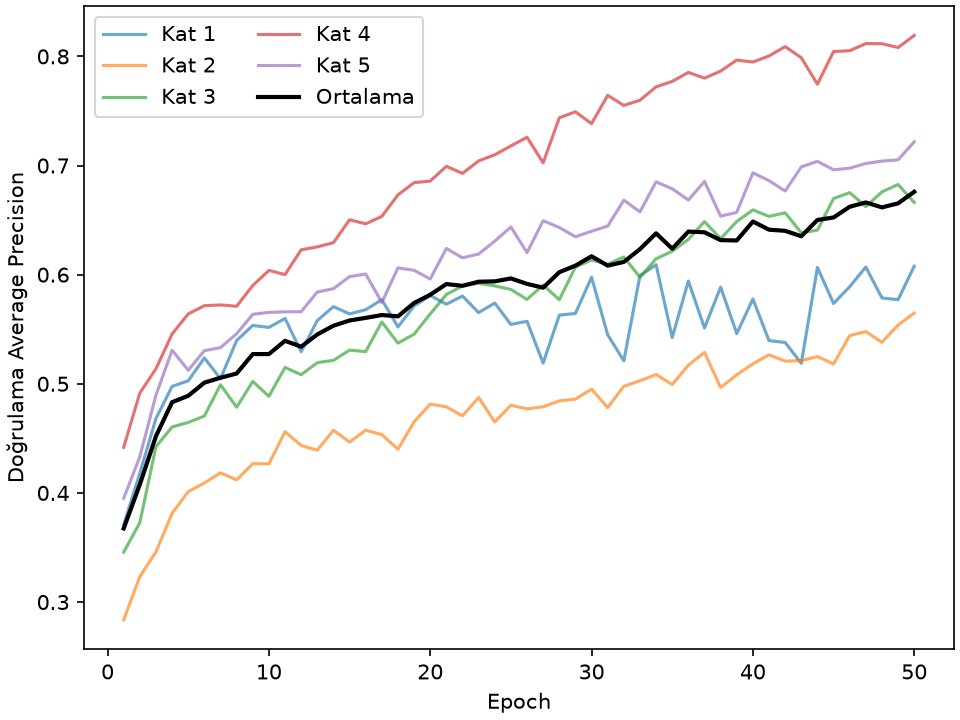

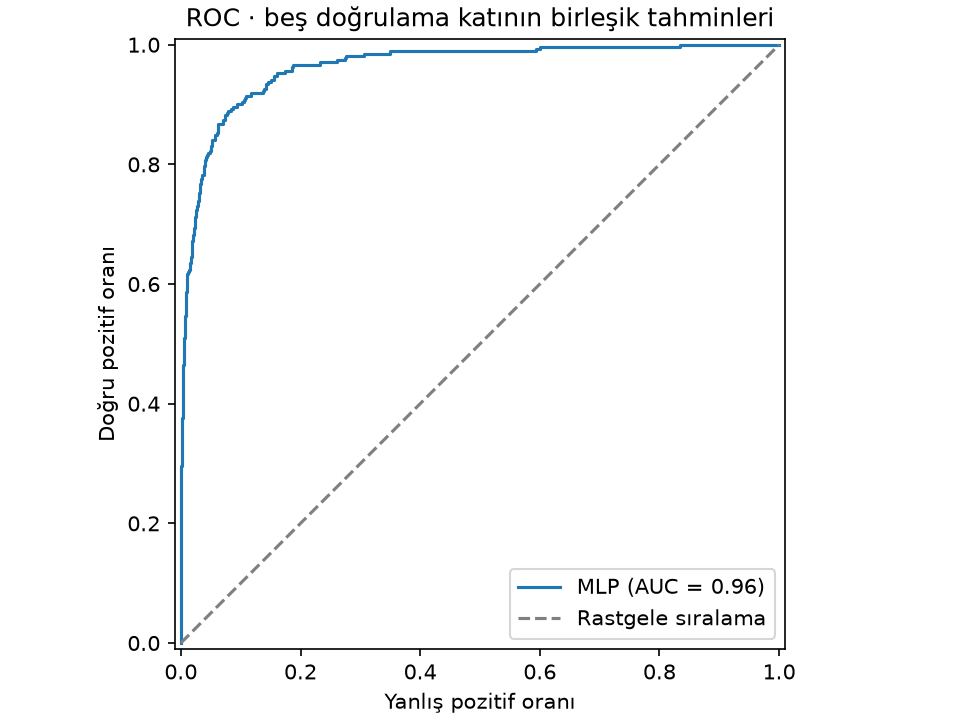

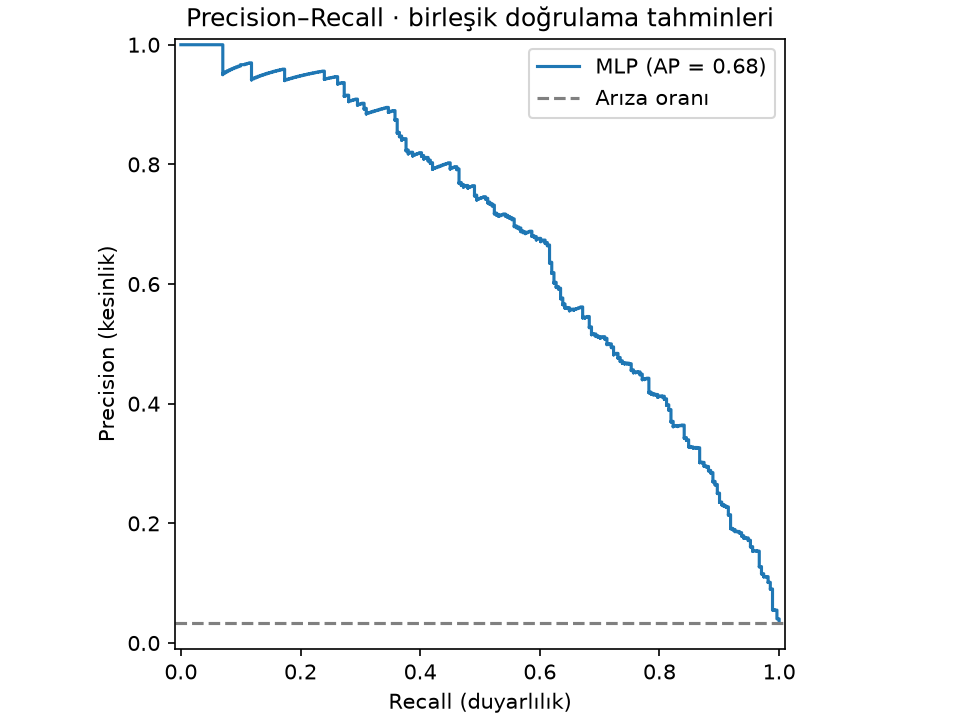

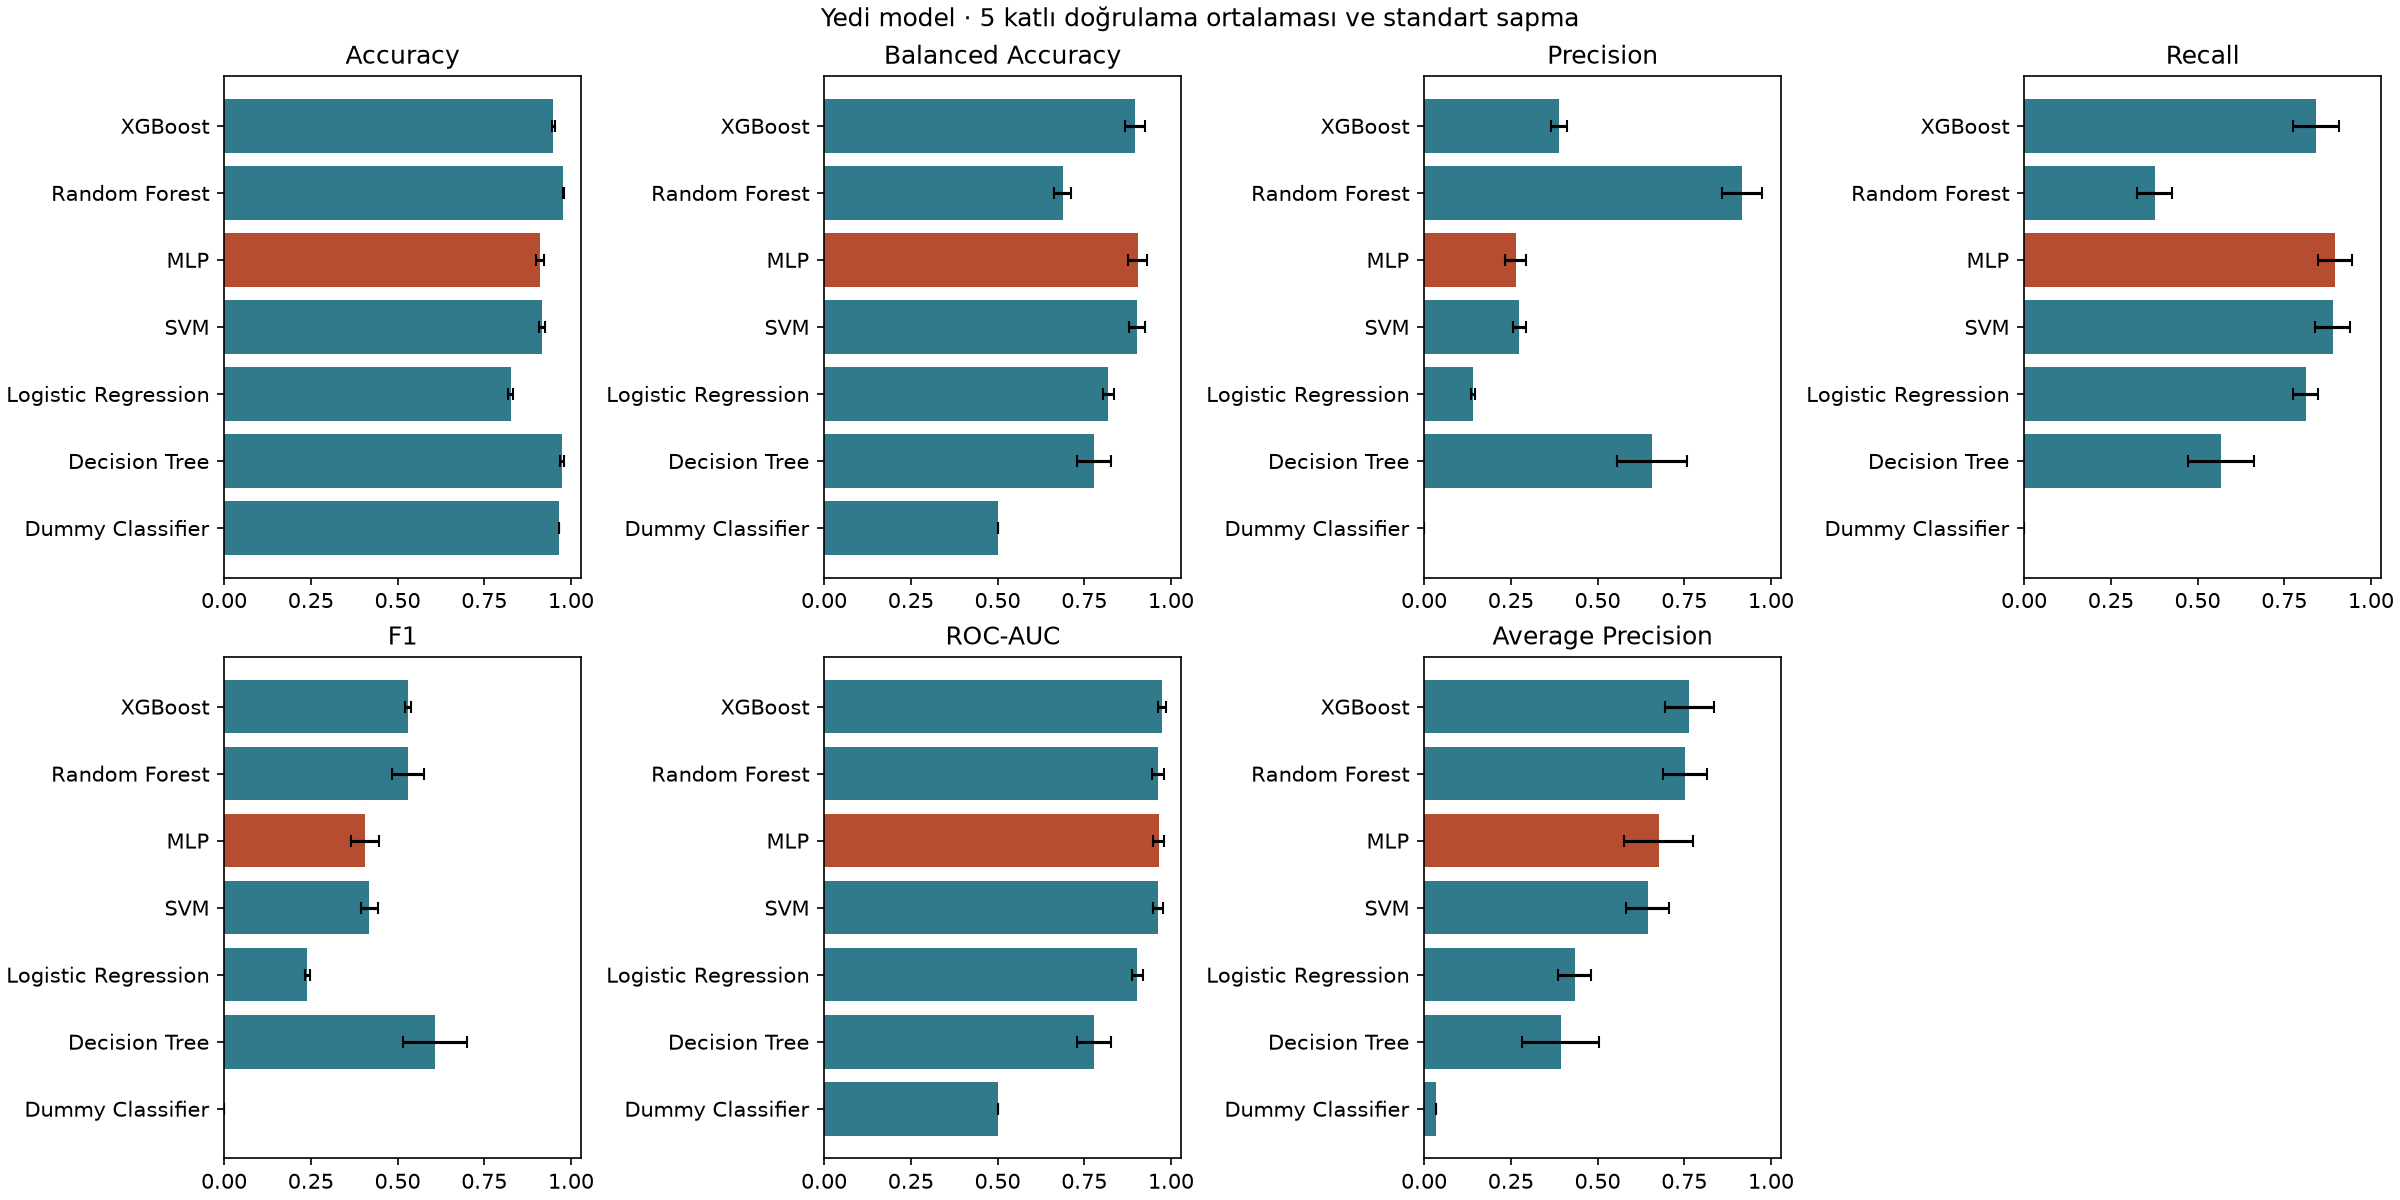

In [6]:
save_results(folds, history, comparison, y_train, oof_scores)
for filename in (
    "architecture.png", "training_loss.png", "validation_performance.png",
    "roc_curve.png", "precision_recall_curve.png", "model_comparison.png",
):
    display(Image(filename=str(OUTPUT / filename),
                  width=1100 if filename == "model_comparison.png" else 700))